Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

Upload Dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving heart_cleveland_upload.csv to heart_cleveland_upload (1).csv


Membaca Dataset

In [ ]:
df = pd.read_csv('heart_cleveland_upload.csv')

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


Melihat Informasi Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        297 non-null    int64  
 1   sex        297 non-null    int64  
 2   cp         297 non-null    int64  
 3   trestbps   297 non-null    int64  
 4   chol       297 non-null    int64  
 5   fbs        297 non-null    int64  
 6   restecg    297 non-null    int64  
 7   thalach    297 non-null    int64  
 8   exang      297 non-null    int64  
 9   oldpeak    297 non-null    float64
 10  slope      297 non-null    int64  
 11  ca         297 non-null    int64  
 12  thal       297 non-null    int64  
 13  condition  297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


Statistik Dataset

In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,2.158249,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,0.602694,0.676768,0.835017,0.461279
std,9.049736,0.468500,0.964859,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,0.956690,0.499340
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,2.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,56.000000,1.000000,2.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,0.000000,0.000000
75%,61.000000,1.000000,3.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,1.000000,1.000000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,3.000000,2.000000,1.000000


Mengecek Missing Value

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Mengecek Data Duplikat

In [ ]:
df.duplicated().sum()

np.int64(0)

Distribusi Penyakit Jantung

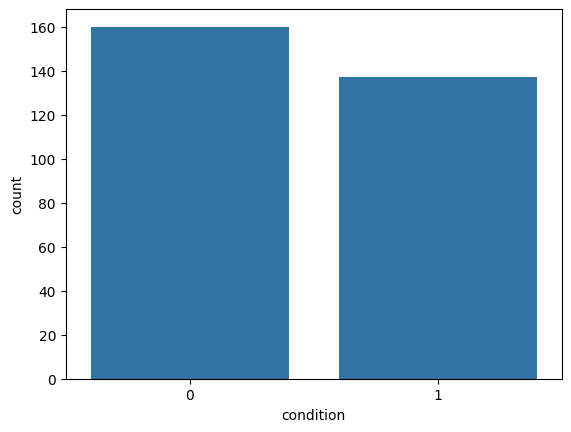

In [ ]:
sns.countplot(x='condition', data=df)

plt.show()

Distribusi Usia

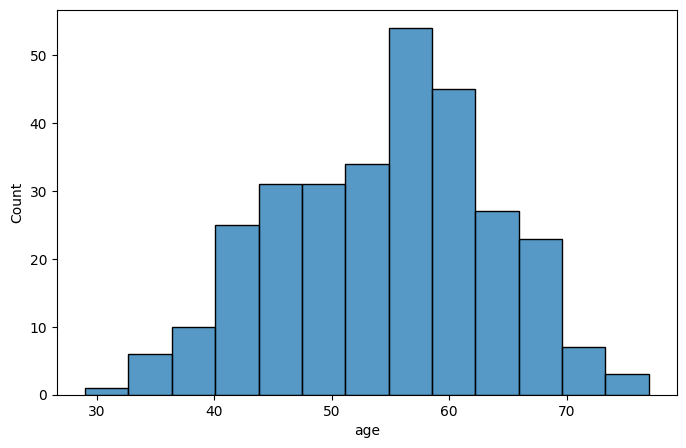

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'])

plt.show()

Heatmap Korelasi

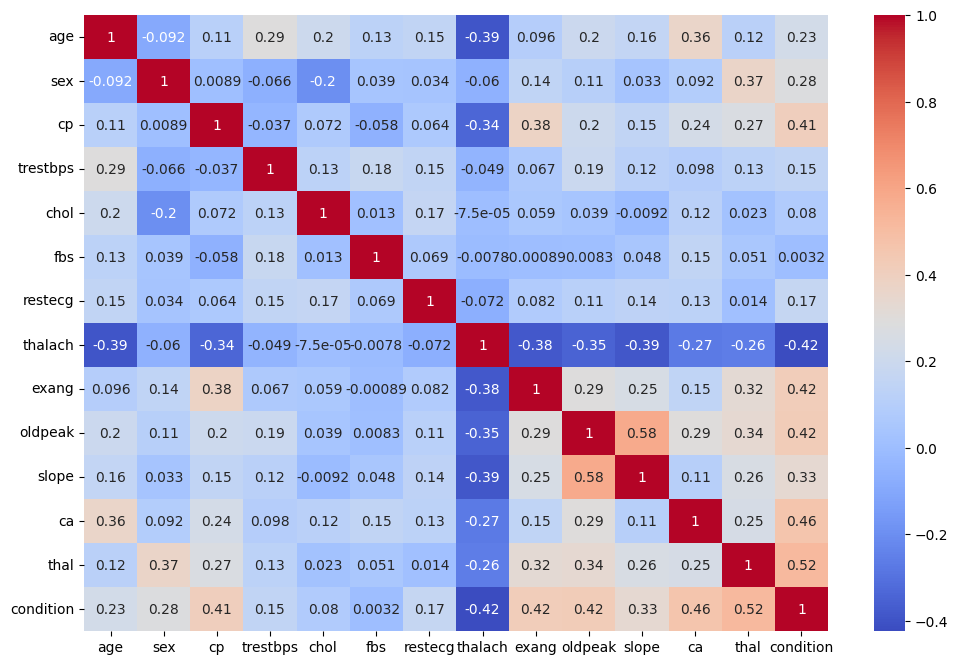

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(),
            annot=True,
            cmap='coolwarm')

plt.show()

Menentukan Variabel X dan Y

In [ ]:
X = df.drop('condition', axis=1)

y = df['condition']

Membagi Data

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Normalisasi Data

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Membuat Model SVM

In [ ]:
svm = SVC()

svm.fit(X_train, y_train)

SVC()

Prediksi SVM

In [ ]:
y_pred_svm = svm.predict(X_test)

Evaluasi SVM
Accuracy

In [ ]:
acc_svm = accuracy_score(
    y_test,
    y_pred_svm
)

print(acc_svm)

0.7333333333333333


Classification Report SVM

In [ ]:
print(
    classification_report(
        y_test,
        y_pred_svm
    )
)

              precision    recall  f1-score   support

           0       0.79      0.69      0.73        32
           1       0.69      0.79      0.73        28

    accuracy                           0.73        60
   macro avg       0.74      0.74      0.73        60
weighted avg       0.74      0.73      0.73        60



Confusion Matrix SVM

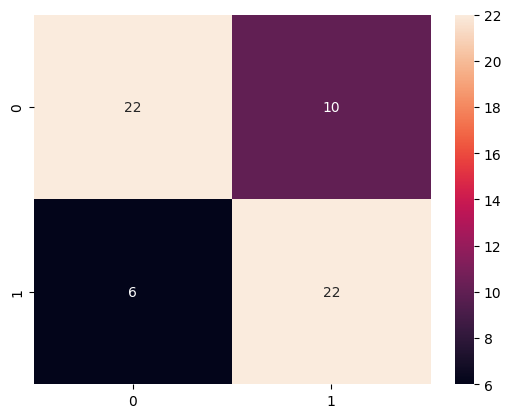

In [ ]:
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm
)

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d'
)

plt.show()

Model Decision Tree

In [ ]:
dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(random_state=42)

Prediksi Decision Tree

In [ ]:
y_pred_dt = dt.predict(X_test)

Evaluasi Decision Tree
Accuracy

In [ ]:
acc_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print(acc_dt)

0.7666666666666667


Classification Report

In [ ]:
print(
    classification_report(
        y_test,
        y_pred_dt
    )
)

              precision    recall  f1-score   support

           0       0.80      0.75      0.77        32
           1       0.73      0.79      0.76        28

    accuracy                           0.77        60
   macro avg       0.77      0.77      0.77        60
weighted avg       0.77      0.77      0.77        60



Confusion Matrix

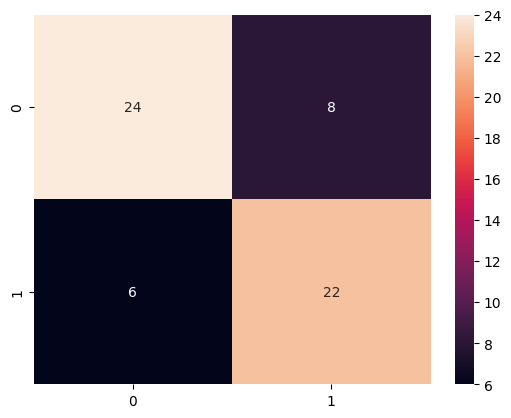

In [ ]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt
)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d'
)

plt.show()

Membandingkan Hasil

In [ ]:
hasil = pd.DataFrame({
    'Algoritma':[
        'SVM',
        'Decision Tree'
    ],
    'Accuracy':[
        acc_svm,
        acc_dt
    ]
})

hasil

,Algoritma,Accuracy
0,SVM,0.733333
1,Decision Tree,0.766667


Visualisasi Perbandingan

```
# This is formatted as code
```



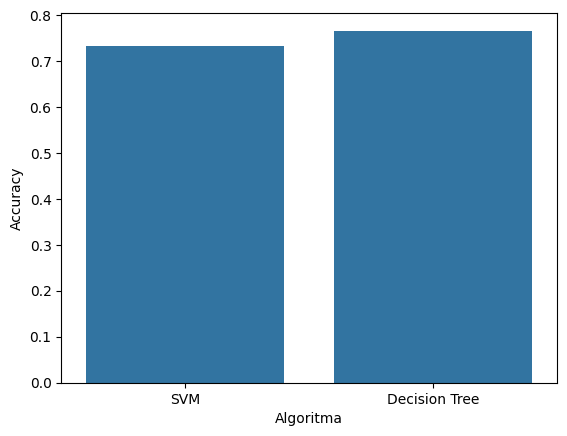

In [ ]:
sns.barplot(
    x='Algoritma',
    y='Accuracy',
    data=hasil
)

plt.show()

Distribusi Jenis Kelamin

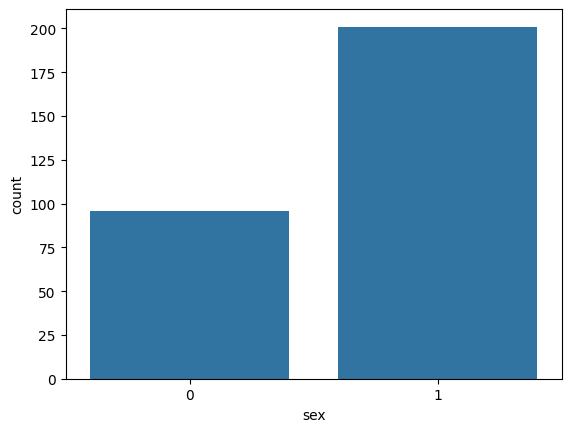

In [ ]:
sns.countplot(x='sex', data=df)
plt.show()

Distribusi Kolesterol

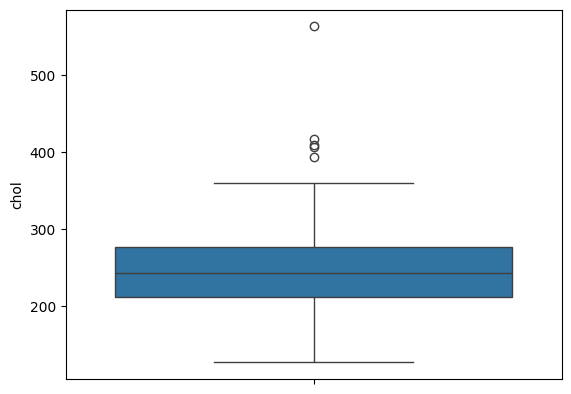

In [ ]:
sns.boxplot(y=df['chol'])
plt.show()

Distribusi Tekanan Darah

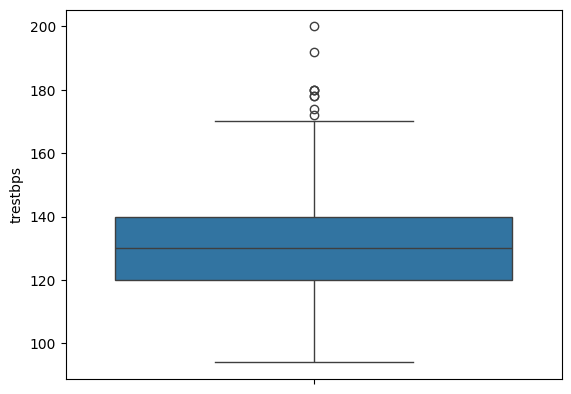

In [ ]:
sns.boxplot(y=df['trestbps'])
plt.show()